In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import sklearn as sk
from sklearn import metrics
from sklearn.metrics import r2_score

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression



In [3]:
df=pd.read_csv("data-tax-gnp-bd.csv")
df.head()

,YEAR,GNP,POPULATION,TAX
0,1980,1499.68,82.498,19.400
1,1981,1583.50,84.764,22.500
2,1982,1634.27,87.061,24.400
3,1983,1709.60,89.400,27.000
4,1984,1781.02,91.804,32.265


In [4]:
df

,YEAR,GNP,POPULATION,TAX
0,1980,1499.68,82.498,19.400
1,1981,1583.50,84.764,22.500
2,1982,1634.27,87.061,24.400
3,1983,1709.60,89.400,27.000
4,1984,1781.02,91.804,32.265
5,1985,1847.70,94.288,39.105
6,1986,1921.33,96.852,45.140
7,1987,1977.65,99.477,50.650
8,1988,2024.88,102.133,56.650
9,1989,2111.92,104.779,64.455


In [5]:
df.shape

(40, 4)

In [6]:
df.columns

Index(['YEAR', 'GNP', 'POPULATION', 'TAX'], dtype='str')

In [7]:
df.describe()

,YEAR,GNP,POPULATION,TAX
count,40.000000,40.000000,40.000000,40.000000
mean,1999.500000,4422.409750,128.143125,550.697775
std,11.690452,2772.821477,25.777876,671.634099
min,1980.000000,1499.680000,82.498000,19.400000
25%,1989.750000,2184.820000,106.734250,108.597000
50%,1999.500000,3469.280000,131.175000,224.658500
75%,2009.250000,5999.877500,149.908500,700.035000
max,2019.000000,11461.940000,166.586000,2547.920000


<Axes: xlabel='POPULATION', ylabel='GNP'>

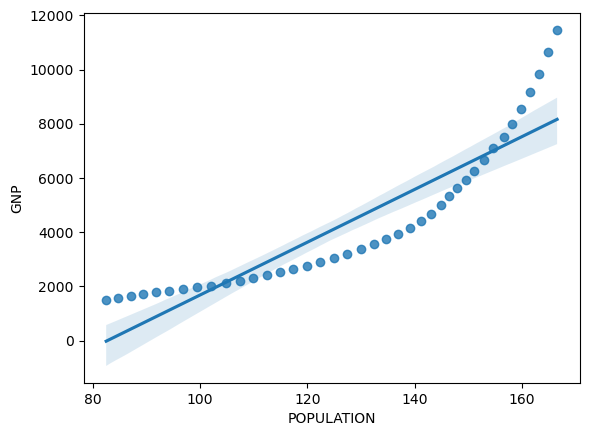

In [8]:
sns.regplot(x=df.POPULATION, y=df.GNP)

<Axes: xlabel='POPULATION', ylabel='GNP'>

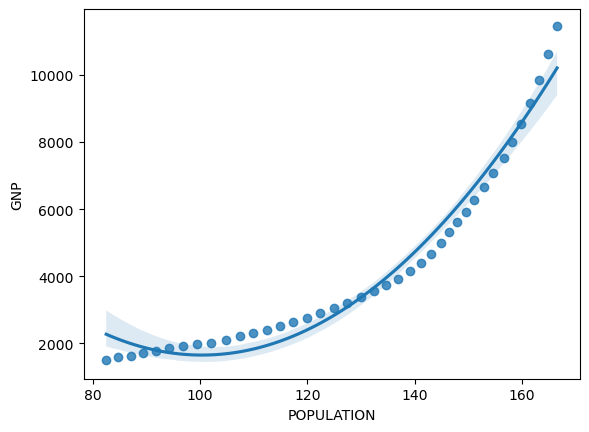

In [9]:
sns.regplot(x=df.POPULATION, y=df.GNP ,data=df,order=2)

<Axes: xlabel='POPULATION', ylabel='GNP'>

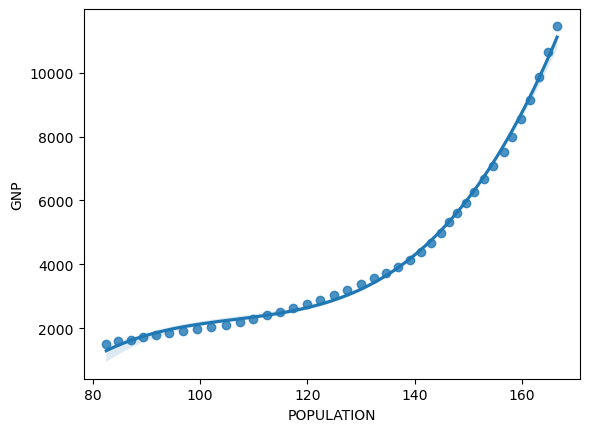

In [10]:
sns.regplot(x=df.POPULATION, y=df.GNP ,data=df,order=3)

In [11]:
from sklearn.preprocessing import PolynomialFeatures


x=df['POPULATION'].values.reshape(-1,1)
y=df['GNP'].values.reshape(-1,1)

x_train, x_test , y_train, y_test= train_test_split(
    x, y, test_size=0.25, random_state=5
)

# pf=PolynomialFeatures(degree=3)
# x_train_poly=pf.fit_transform(x_train)
# x_test_poly=pf.fit_transform(x_test)

In [12]:
pf=PolynomialFeatures(degree=3)
x_=pf.fit_transform(x)
x_test_=pf.fit_transform(x_test)

In [13]:
poly=LinearRegression()
poly.fit(x_,y)
poly.coef_

array([[ 0.        , -0.01080643, -1.32921341,  0.00892245]])

In [14]:
y_predict=poly.predict(x_test_)

In [15]:
print(f"Coefficent : {poly.coef_}")
print(f"Intercept : {poly.intercept_}")

print(f"MAE : {metrics.mean_absolute_error(y_test,y_predict)}")
print(f"MSE : {metrics.mean_squared_error(y_test,y_predict)}")
print(f"RMSE : {metrics.root_mean_squared_error(y_test,y_predict)}" )

accuracy=poly.score(x_test_,y_test)
print(f"AccuracyII : {accuracy*100} %")
print(f"R2_Score : {r2_score(y_test,y_predict)}")


Coefficent : [[ 0.         -0.01080643 -1.32921341  0.00892245]]
Intercept : [6147.62773744]
MAE : 264.39354612528086
MSE : 137275.70622670194
RMSE : 370.50736325571444
AccuracyII : 98.234757691064 %
R2_Score : 0.98234757691064


In [16]:
new={ "POPULATION" : ["200"]}
newdf=pd.DataFrame(new)



In [17]:
newdfReshape=newdf["POPULATION"].values.reshape(-1,1)

plyfit=pf.fit_transform(newdf)

poly.predict(plyfit)

array([[24356.5423306]])

In [18]:
linreg=LinearRegression()
linreg.fit(x_train, y_train)
y_lin_predict=linreg.predict(x_test)

In [21]:
print("Coefficient : ", linreg.coef_)
print("Intercept : ", linreg.intercept_)

accuracy2=linreg.score(x_test,y_test)
print("AccuracyII : ",accuracy2*100,"%")


print(f"MAE : {metrics.mean_absolute_error(y_test,y_lin_predict)}")
print(f"MSE : {metrics.mean_squared_error(y_test,y_lin_predict)}")
print(f"RMSE : {metrics.root_mean_squared_error(y_test,y_lin_predict)}" )

print("R2_Score : ",r2_score(y_test,y_lin_predict))

Coefficient :  [[100.14883252]]
Intercept :  [-8431.28106286]
AccuracyII :  72.28512826943647 %
MAE : 1299.7312045114136
MSE : 2155272.7183888806
RMSE : 1468.084710903591
R2_Score :  0.7228512826943647
